In [15]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt 

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [2]:
df

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"[r, python, sql, nosql, power bi, tableau]","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"[python, sql, c#, azure, airflow, dax, docker,...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"[python, c++, java, matlab, aws, tensorflow, k...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"[bash, python, oracle, aws, ansible, puppet, j...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785736,Software Engineer,DevOps Engineer,Singapura,melalui Trabajo.org,Pekerjaan tetap,False,Singapore,2023-03-13 06:16:16,False,False,Singapore,NaN,NaN,NaN,CAREERSTAR INTERNATIONAL PTE. LTD.,"[bash, python, perl, linux, unix, kubernetes, ...","{'os': ['linux', 'unix'], 'other': ['kubernete..."
785737,Data Analyst,CRM Data Analyst,"Bad Rodach, Jerman",melalui BeBee Deutschland,Pekerjaan tetap,False,Germany,2023-03-12 06:18:18,False,False,Germany,NaN,NaN,NaN,HABA FAMILYGROUP,"[sas, sas, sql, excel]","{'analyst_tools': ['sas', 'excel'], 'programmi..."
785738,Business Analyst,Commercial Analyst - Start Now,Malaysia,melalui Ricebowl,Pekerjaan tetap,False,Malaysia,2023-03-12 06:32:36,False,False,Malaysia,NaN,NaN,NaN,Lendlease Corporation,"[powerpoint, excel]","{'analyst_tools': ['powerpoint', 'excel']}"
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,"[python, go, nosql, sql, mongo, shell, mysql, ...","{'cloud': ['aws', 'snowflake', 'azure', 'redsh..."


### Problem #1 Statement:
Create a pie chart to show the proportion of job postings that mention health insurance for Data Analyst roles only:

Create a new DataFrame called df_DA that only gets Data Analyst roles.
Then count the number of data analyst roles that mention or not mention health insurance by using the job_health_insurance column.
Plot this using plt.pie(), setting labels parameter to ['No', 'Yes'], startangle to 90, and format values to display similarly to 23.1%.
Set the title to 'Proportion of Data Analyst Jobs Mentioning Health Insurance'.

In [ ]:
df_DA = df[df["job_title_short"] == "Data Analyst"].copy() # create a dataframe with Data Analyst only; df_DA is just the view of original df that shows only Data Analyst, but if we make changes in df_DA then original df will alter, so we make copy of original df and use it for df_DA

df_DA["job_health_insurance"].value_counts() # value_counts as single series - column

job_health_insurance
False    171351
True      24724
Name: count, dtype: int64

Text(0.5, 1.0, 'Proportion of Data Analyst Jobs Mentioning Health Insurance')

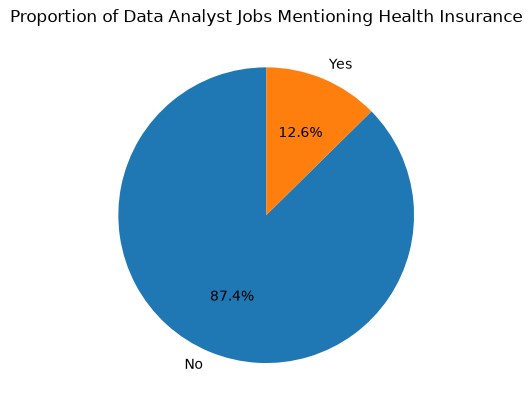

In [10]:
# using pandas way:
df_DA["job_health_insurance"].value_counts().plot(kind="pie", startangle=90, autopct="%1.1f%%", labels=["No", "Yes"])
plt.title("Proportion of Data Analyst Jobs Mentioning Health Insurance")

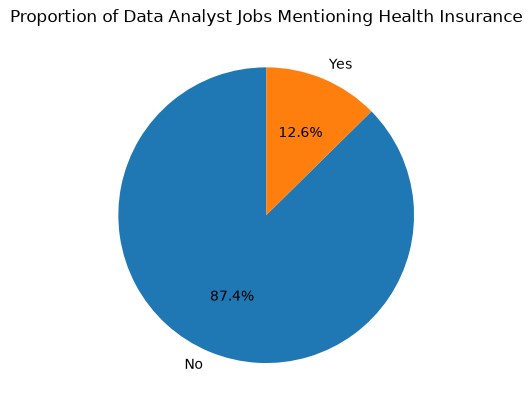

In [9]:
# using matplotlib way:

plt.pie(df_DA["job_health_insurance"].value_counts(), labels=['No', 'Yes'], autopct='%1.1f%%', startangle=90)
plt.title('Proportion of Data Analyst Jobs Mentioning Health Insurance')
plt.show()

# First label ('No') is assigned to the 1st slice (majority count).

# Second label ('Yes') is assigned to the 2nd slice (minority count).

### Problem #2 Statement:
Create a pie chart showing the count of job postings per job schedule types (for only jobs that are either 'Full-time' and 'Part-time') in the DataFrame.
Create a DataFrame to filter out these job_schedule_type called df_ft_pt.
Plot this using plt.pie(), setting labels parameter to the index, startangle to 90, and format values to display similarly to 23.1%.
Add a title 'Job Schedule Full-time vs. Part-time'.

In [12]:
df_ft_pt = df[df["job_schedule_type"].isin(["Full-time", "Part-time"])] 

df_ft_pt

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"[r, python, sql, nosql, power bi, tableau]","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"[python, sql, c#, azure, airflow, dax, docker,...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"[python, c++, java, matlab, aws, tensorflow, k...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"[bash, python, oracle, aws, ansible, puppet, j...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785702,Business Analyst,Aeronautical Analyst,"Gdańsk, Poland",via Praca Trabajo.org,Full-time,False,Poland,2023-04-26 06:24:52,False,False,Poland,NaN,NaN,NaN,NAVBLUE,NaN,NaN
785703,Data Analyst,Data Analyst - CRYPTOGRAPHY - Full-time,Anywhere,via Snagajob,Full-time,True,"Texas, United States",2023-01-28 06:02:55,True,False,United States,NaN,NaN,NaN,Axelon Services Corporation,NaN,NaN
785704,Business Analyst,Business Analyst,"Prague, Czechia",via Trabajo.org,Full-time,False,Czechia,2023-01-16 06:35:20,False,False,Czechia,NaN,NaN,NaN,Cleverlance,NaN,NaN
785705,Data Analyst,Expert Business Data Analyst - Now Hiring,"Oakland, CA",via Snagajob,Full-time,False,"California, United States",2023-01-09 06:00:25,False,False,United States,NaN,NaN,NaN,PG&E Corporation,"[sql, python, tableau]","{'analyst_tools': ['tableau'], 'programming': ..."


In [13]:
df_ft_pt["job_schedule_type"].value_counts()

job_schedule_type
Full-time    701727
Part-time      7881
Name: count, dtype: int64

<Axes: title={'center': 'Job Schedule Full-time vs. Part-time'}>

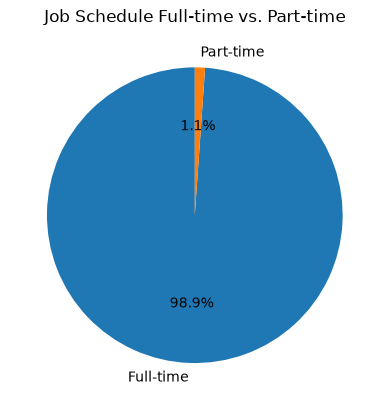

In [18]:
# pandas way
df_ft_pt["job_schedule_type"].value_counts().plot(kind="pie", startangle=90, autopct="%1.1f%%", title="Job Schedule Full-time vs. Part-time")

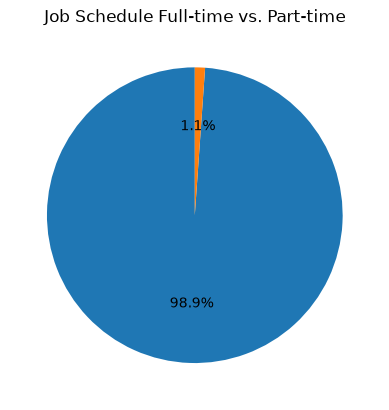

In [20]:
# matplotlib way
plt.pie(df_ft_pt["job_schedule_type"].value_counts(), startangle=90, autopct="%1.1f%%")
plt.title("Job Schedule Full-time vs. Part-time")
plt.show()

In [ ]:
# If you want to use comparison operators, use the pipe operator (|) and wrap each separate condition in parentheses:
# df_ft_pt = df[(df['job_schedule_type'] == 'Full-time') | (df['job_schedule_type'] == 'Part-time')].copy()

### Problem #3 Statement:
Create a pie chart to show the distribution of job postings that mention a degree in the job posting versus those that do not.
Only get job postings located in the US, create a new DataFrame with this filtered data called df_US.
Use the job_no_degree_mention column for this purpose.
Customize the pie chart by exploding the slice for jobs that do not mention a degree. (Use the explode parameter set to (0, 0.1) inside of plt.pie())
Set the chart title as 'Distribution of Jobs Mentioning Degrees for US Job Postings'.

In [22]:
df_US = df[df["job_country"] == "United States"].copy()

In [23]:
df_US["job_no_degree_mention"].value_counts()

job_no_degree_mention
False    169655
True      36637
Name: count, dtype: int64

<Axes: title={'center': 'Distribution of Jobs Mentioning Degrees for US Job Postings'}>

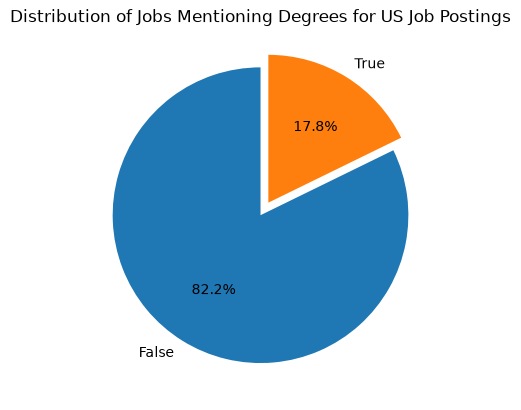

In [31]:
df_US["job_no_degree_mention"].value_counts().plot(kind="pie", startangle=90, autopct="%1.1f%%", title="Distribution of Jobs Mentioning Degrees for US Job Postings", explode=(0, 0.1))

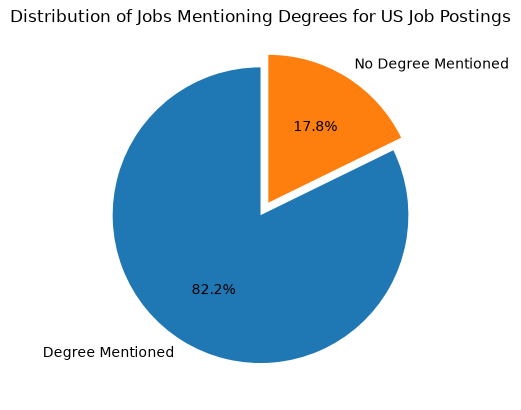

In [30]:
plt.pie(df_US["job_no_degree_mention"].value_counts(),startangle=90, autopct="%1.1f%%", labels=["Degree Mentioned", "No Degree Mentioned"], explode=(0, 0.1))
plt.title("Distribution of Jobs Mentioning Degrees for US Job Postings")
plt.show()